# Tarea 1 — Extracción de descriptores de patrones en imágenes
**Reconocimiento de Patrones en Imágenes — Laura Romero**

**Supuestos y decisiones de diseño:**
- Se detectó que las 36 letras de la imagen están completamente separadas entre sí (ninguna se toca ni se superpone), por lo que la segmentación se hace con componentes conexas (`cv2.connectedComponents`) sin necesidad de técnicas adicionales de separación (watershed, etc.).
- Los momentos de Hu se reportan en escala logarítmica (`-sign(h)*log10(|h|)`), estándar en la literatura, ya que los valores crudos tienen órdenes de magnitud muy distintos entre sí.
- La redondez se calcula con la fórmula clásica de circularidad `R = 4·pi·Área / Perímetro²` (R=1 para un círculo perfecto).
- El ángulo de la elipse se obtiene con el **método de Fitzgibbon (1996)** visto en clases (mismas funciones `fitzgibbon`/`parametros` del material de clase), aplicado sobre las coordenadas del contorno externo de cada letra, centradas en su propio origen para evitar inestabilidad numérica del ajuste (las coordenadas de píxeles sin centrar generan un mal condicionamiento en el problema de eigenvalores generalizado).

In [1]:
# Uso: dejar este notebook junto a 'sopa_letras.png' y ejecutar todas las celdas en orden (Run All).
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

IMG_PATH = 'sopa_letras.png'

## Paso 1: Cargar la imagen y pasar a escala de grises

`cv2.imread` carga la imagen en formato BGR. La convertimos a RGB para mostrarla con colores correctos en matplotlib, y por separado obtenemos una versión en escala de grises, que es la que necesitamos para binarizar.

Tamaño de la imagen: (512, 512, 3)
Rango de intensidades (gris): 0 - 255


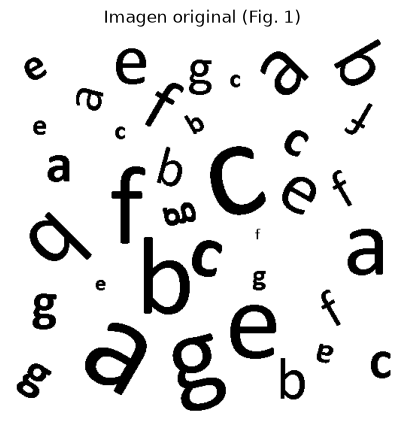

In [2]:
img_color = cv2.imread(IMG_PATH)
img_rgb = cv2.cvtColor(img_color, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(img_color, cv2.COLOR_BGR2GRAY)

print(f'Tamaño de la imagen: {img_color.shape}')
print(f'Rango de intensidades (gris): {gray.min()} - {gray.max()}')

plt.figure(figsize=(5, 5))
plt.imshow(img_rgb)
plt.title('Imagen original (Fig. 1)')
plt.axis('off')
plt.show()

## Paso 2: Binarización con el método de Otsu

Necesitamos separar las letras (primer plano) del fondo blanco. Usamos el método de **Otsu**, que encuentra automáticamente el umbral óptimo a partir del histograma de la imagen (en vez de fijar un valor a mano, como se hace en los ejemplos de clase con umbral fijo=100). Usamos `THRESH_BINARY_INV` porque las letras son oscuras sobre fondo claro, y queremos que el primer plano (las letras) quede en blanco (255).

Valores de gris únicos en la imagen: 2
Umbral encontrado automáticamente por Otsu: 0.0


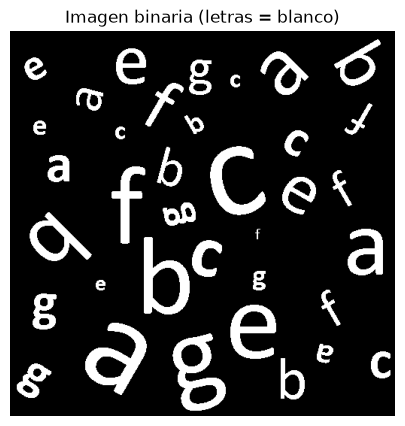

In [3]:
umbral, bw = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

print(f'Valores de gris únicos en la imagen: {len(np.unique(gray))}')
print(f'Umbral encontrado automáticamente por Otsu: {umbral}')
# nota: da 0.0 porque esta imagen ya viene binaria (solo valores 0 y 255,
# sin antialiasing); si la imagen tuviera bordes suaves, Otsu buscaría
# un valor intermedio (ej. ~127) para separar letras del fondo.

plt.figure(figsize=(5, 5))
plt.imshow(bw, cmap='gray')
plt.title('Imagen binaria (letras = blanco)')
plt.axis('off')
plt.show()

## Paso 3: Segmentar cada letra (componentes conexas)

Cada letra debe analizarse por separado. Usamos `cv2.connectedComponentsWithStats`, que etiqueta cada región blanca conectada con un número distinto (0 = fondo). Verificamos primero que efectivamente cada letra quedó aislada (ninguna se tocó con otra) y descartamos etiquetas demasiado pequeñas (ruido/antialiasing).

Componentes conexas encontradas (incluye fondo): 37
Letras válidas después de filtrar ruido (area >= 20): 36


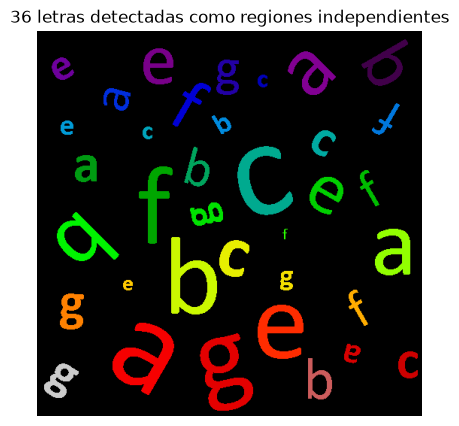

In [9]:
n_labels, labels, stats, _ = cv2.connectedComponentsWithStats(bw, connectivity=8)
AREA_MIN = 20  # descarta ruido/artefactos de antialiasing

areas = stats[1:, cv2.CC_STAT_AREA]
etiquetas_validas = [i for i in range(1, n_labels) if stats[i, cv2.CC_STAT_AREA] >= AREA_MIN]

print(f'Componentes conexas encontradas (incluye fondo): {n_labels}')
print(f'Letras válidas después de filtrar ruido (area >= {AREA_MIN}): {len(etiquetas_validas)}')

# visualizamos las etiquetas con colores distintos para confirmar que cada letra quedó separada
labels_vis = np.uint8(labels % 256)
plt.figure(figsize=(5, 5))
plt.imshow(labels_vis, cmap='nipy_spectral')
plt.title(f'{len(etiquetas_validas)} letras detectadas como regiones independientes')
plt.axis('off')
plt.show()

## Paso 4: Funciones para el ajuste de elipse (método de Fitzgibbon, 1996)

Estas son las mismas funciones vistas en clase para ajustar una elipse a un conjunto de puntos del contorno, resolviendo el problema de mínimos cuadrados con restricción `aᵀCa = 1` vía eigenvalores generalizados (`S·a = λ·C·a`).

Nota: se agregó `np.real(...)` porque, al no centrar las coordenadas del contorno antes de resolver el sistema, el problema queda mal condicionado numéricamente y `np.linalg.eig` puede devolver una parte imaginaria espuria (del orden de 1e-10) aunque la solución sea real por construcción. Por eso más adelante centramos las coordenadas de cada letra antes de llamar a estas funciones.

In [10]:
def fitzgibbon(x, y):
    n = x.shape[0]
    D = [x**2, x*y, y**2, x, y, np.ones((n, 1))]
    D = np.hstack(D)
    S = np.matmul(D.T, D)                   # matriz de dispersión
    C = np.zeros((6, 6))
    C[0, 2] = 2; C[1, 1] = -1; C[2, 0] = 2   # matriz de restricción

    E, V = np.linalg.eig(np.dot(np.linalg.inv(S), C))
    E = np.real(E); V = np.real(V)

    idx = np.argwhere((E > 0) & (~np.isinf(E)))
    if len(idx) == 0:
        idx = np.argwhere(~np.isinf(E))[:1]
    params = V[:, idx[0]]
    return params.ravel()


def parametros(x, y):
    a, b, c, d, e, f = fitzgibbon(x, y)
    alpha = np.arctan2(b, a - c) / 2

    ct, st = np.cos(alpha), np.sin(alpha)
    ap = a*ct*ct + b*ct*st + c*st*st
    cp = a*st*st - b*ct*st + c*ct*ct

    T = np.array([[a, b/2], [b/2, c]])
    t = -1 * np.matmul(np.linalg.inv(2*T), np.array([d, e]).reshape(2, 1))

    val = np.matmul(t.T, np.matmul(T, t))
    scale = 1 / (val - f)

    r1 = 1 / np.sqrt(scale * ap)
    r2 = 1 / np.sqrt(scale * cp)

    return r1.item(), r2.item(), t[0].item(), t[1].item(), alpha

print('Funciones fitzgibbon() y parametros() definidas.')

Funciones fitzgibbon() y parametros() definidas.


## Paso 5: Probar el método con UNA sola letra (ejemplo)

Antes de aplicar el proceso a las 36 letras, lo probamos con una sola (la más grande, para que se vea claro) y vamos imprimiendo cada descriptor a medida que se calcula, para verificar que el método funciona bien.

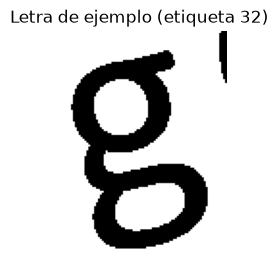

In [11]:
# elegimos la letra con mayor área como ejemplo (fácil de visualizar)
etiqueta_ejemplo = max(etiquetas_validas, key=lambda i: stats[i, cv2.CC_STAT_AREA])
mask_ejemplo = np.uint8(labels == etiqueta_ejemplo)

# recorte alrededor de la letra, solo para visualizar mejor
x0, y0, w0, h0, _ = stats[etiqueta_ejemplo]
margen = 10
recorte = img_rgb[max(y0-margen,0):y0+h0+margen, max(x0-margen,0):x0+w0+margen]

plt.figure(figsize=(3, 3))
plt.imshow(recorte)
plt.title(f'Letra de ejemplo (etiqueta {etiqueta_ejemplo})')
plt.axis('off')
plt.show()

In [12]:
# contorno externo de la letra de ejemplo
contornos, _ = cv2.findContours(np.uint8(mask_ejemplo*255), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
contorno_ejemplo = max(contornos, key=cv2.contourArea)
print(f'Puntos en el contorno: {len(contorno_ejemplo)}')

# (1) momentos de Hu, en escala logarítmica
m = cv2.moments(mask_ejemplo, binaryImage=True)
hu = cv2.HuMoments(m).flatten()
hu_log = -np.sign(hu) * np.log10(np.abs(hu))
print(f'Hu (crudos):       {hu[:4]}')
print(f'Hu (log-escala):   {hu_log[:4]}')

# (2) perímetro
perimetro_ej = cv2.arcLength(contorno_ejemplo, True)
print(f'Perímetro: {perimetro_ej:.2f} píxeles')

# (3) redondez = 4*pi*Area/Perimetro^2
area_ej = m['m00']
redondez_ej = 4 * np.pi * area_ej / (perimetro_ej ** 2)
print(f'Área: {area_ej:.1f} píxeles, Redondez: {redondez_ej:.4f}  (1.0 = círculo perfecto)')

# centro de masa (para ubicar la letra más adelante)
cx_ej, cy_ej = m['m10']/m['m00'], m['m01']/m['m00']
print(f'Centro de masa: ({cx_ej:.1f}, {cy_ej:.1f})')

Puntos en el contorno: 340
Hu (crudos):       [3.90154544e-01 3.61479301e-02 1.43755261e-03 2.28846206e-04]
Hu (log-escala):   [0.40876333 1.44191657 2.84237625 3.64045628]
Perímetro: 391.36 píxeles
Área: 3031.0 píxeles, Redondez: 0.2487  (1.0 = círculo perfecto)
Centro de masa: (248.5, 455.5)


Semiejes de la elipse ajustada: r1=47.13, r2=27.24
Ángulo de orientación: 79.93 grados


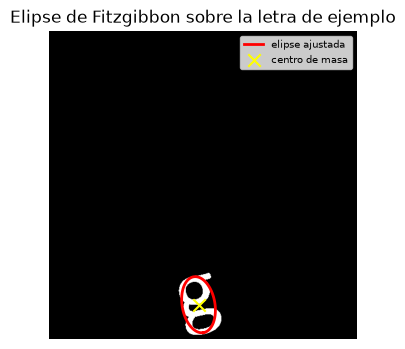

In [13]:
# (4) ángulo de la elipse: centramos las coordenadas del contorno antes de ajustar
pts = contorno_ejemplo.reshape(-1, 2).astype(float)
x_pts = pts[:, 0].reshape(-1, 1)
y_pts = pts[:, 1].reshape(-1, 1)
xm, ym = x_pts.mean(), y_pts.mean()

r1_ej, r2_ej, tcx_ej, tcy_ej, alpha_ej = parametros(x_pts - xm, y_pts - ym)
angulo_ej_deg = np.degrees(alpha_ej)
print(f'Semiejes de la elipse ajustada: r1={r1_ej:.2f}, r2={r2_ej:.2f}')
print(f'Ángulo de orientación: {angulo_ej_deg:.2f} grados')

# visualizamos la elipse ajustada sobre la letra, para confirmar que el ángulo tiene sentido
theta = np.linspace(0, 2*np.pi, 100)
R = np.array([[np.cos(alpha_ej), -np.sin(alpha_ej)], [np.sin(alpha_ej), np.cos(alpha_ej)]])
elipse_xy = R @ np.array([r1_ej*np.cos(theta), r2_ej*np.sin(theta)])
elipse_x = elipse_xy[0] + xm
elipse_y = elipse_xy[1] + ym

plt.figure(figsize=(4, 4))
plt.imshow(mask_ejemplo, cmap='gray')
plt.plot(elipse_x, elipse_y, color='red', linewidth=2, label='elipse ajustada')
plt.scatter([cx_ej], [cy_ej], color='yellow', marker='x', s=80, label='centro de masa')
plt.legend(loc='upper right', fontsize=7)
plt.title('Elipse de Fitzgibbon sobre la letra de ejemplo')
plt.axis('off')
plt.show()

## Paso 6: Repetir el mismo proceso para las 36 letras

Ahora que confirmamos que el método funciona bien con una letra, repetimos exactamente los mismos pasos (Hu, perímetro, redondez, ángulo de elipse, centro de masa) para cada una de las 36 letras detectadas, e imprimimos el avance letra por letra.

In [14]:
filas = []
centros = []

for etiqueta in etiquetas_validas:
    mask = np.uint8(labels == etiqueta)

    contornos, _ = cv2.findContours(np.uint8(mask*255), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    contorno = max(contornos, key=cv2.contourArea)

    # (1) Hu
    m = cv2.moments(mask, binaryImage=True)
    hu = cv2.HuMoments(m).flatten()
    hu_log = -np.sign(hu) * np.log10(np.abs(hu))

    # (2) perímetro
    perimetro = cv2.arcLength(contorno, True)

    # (3) redondez
    area = m['m00']
    redondez = 4 * np.pi * area / (perimetro ** 2)

    # centro de masa
    cx, cy = m['m10'] / m['m00'], m['m01'] / m['m00']
    centros.append((cx, cy))

    # (4) ángulo de la elipse (coordenadas centradas)
    pts = contorno.reshape(-1, 2).astype(float)
    x_pts = pts[:, 0].reshape(-1, 1)
    y_pts = pts[:, 1].reshape(-1, 1)
    xm, ym = x_pts.mean(), y_pts.mean()
    _, _, _, _, alpha = parametros(x_pts - xm, y_pts - ym)
    angulo_deg = np.degrees(alpha)

    letra_id = len(filas) + 1
    print(f'Letra {letra_id:2d} (etiqueta {etiqueta:2d}): '
          f'perimetro={perimetro:7.2f}  redondez={redondez:.4f}  angulo={angulo_deg:7.2f}°  '
          f'centro=({cx:.1f}, {cy:.1f})')

    filas.append({
        'ID': letra_id,
        'Hu1': hu_log[0], 'Hu2': hu_log[1], 'Hu3': hu_log[2], 'Hu4': hu_log[3],
        'Perimetro': round(perimetro, 2),
        'Redondez': round(redondez, 4),
        'Angulo_Elipse_deg': round(angulo_deg, 2),
    })

print(f'\nProceso terminado: {len(filas)} letras procesadas.')

Letra  1 (etiqueta  1): perimetro= 226.35  redondez=0.2973  angulo= -41.86°  centro=(463.1, 44.3)
Letra  2 (etiqueta  2): perimetro= 206.71  redondez=0.2859  angulo=  84.26°  centro=(159.4, 46.2)
Letra  3 (etiqueta  3): perimetro= 251.71  redondez=0.2606  angulo=  42.70°  centro=(364.9, 54.8)
Letra  4 (etiqueta  4): perimetro= 129.20  redondez=0.3516  angulo=  54.69°  centro=(31.9, 49.9)
Letra  5 (etiqueta  5): perimetro= 188.71  redondez=0.2618  angulo=   4.78°  centro=(252.0, 61.2)
Letra  6 (etiqueta  6): perimetro=  67.11  redondez=0.3655  angulo=   0.00°  centro=(298.5, 66.0)
Letra  7 (etiqueta  7): perimetro= 215.18  redondez=0.2030  angulo=  38.99°  centro=(203.2, 93.1)
Letra  8 (etiqueta  8): perimetro= 150.33  redondez=0.2708  angulo=  11.69°  centro=(106.1, 89.0)
Letra  9 (etiqueta  9): perimetro= 153.58  redondez=0.2040  angulo=  39.12°  centro=(464.2, 119.6)
Letra 10 (etiqueta 10): perimetro=  88.91  redondez=0.4499  angulo=  44.94°  centro=(245.3, 123.6)
Letra 11 (etiqueta 

## Paso 7: Resultado final — DataFrame de descriptores

In [15]:
df = pd.DataFrame(filas)
df

,ID,Hu1,Hu2,Hu3,Hu4,Perimetro,Redondez,Angulo_Elipse_deg
0,1,0.371225,1.586559,1.857879,3.135372,226.35,0.2973,-41.86
1,2,0.472206,2.407093,3.040407,3.389876,206.71,0.2859,84.26
2,3,0.439795,1.926086,2.661389,3.347413,251.71,0.2606,42.70
3,4,0.588410,2.780459,3.559487,3.794333,129.20,0.3516,54.69
4,5,0.438636,1.492712,2.952065,3.794001,188.71,0.2618,4.78
5,6,0.534471,1.986342,2.598917,3.069527,67.11,0.3655,0.00
6,7,0.272465,0.670930,1.598230,2.091784,215.18,0.2030,38.99
7,8,0.450886,1.972225,2.666442,3.257356,150.33,0.2708,11.69
8,9,0.271500,0.670138,1.586150,2.069384,153.58,0.2040,39.12
9,10,0.533334,1.909257,2.308902,3.474277,88.91,0.4499,44.94


## Paso 8: Resultado final — centro de masa de cada letra sobre la imagen original

Por requisito del enunciado, el centro de masa se dibuja sobre la imagen original (Fig. 1), no sobre la máscara binaria.

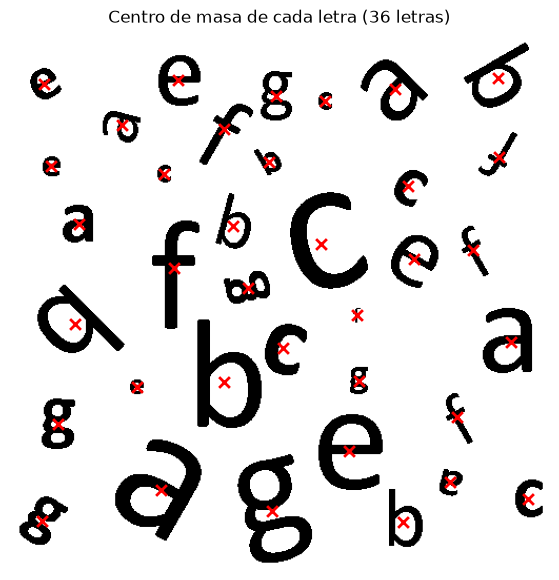

In [16]:
plt.figure(figsize=(7, 7))
plt.imshow(img_rgb)
xs = [c[0] for c in centros]
ys = [c[1] for c in centros]
plt.scatter(xs, ys, c='red', marker='x', s=60, linewidths=2)
plt.title(f'Centro de masa de cada letra ({len(centros)} letras)')
plt.axis('off')
plt.show()